In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.patches as mpatches
import os
import pandas as pd
import networkx as nx
import datetime
import random
import plotly.express as px
import seaborn as sns
from networkx.convert_matrix import from_numpy_array
from scipy.stats import ttest_ind
from LIBS.embedding_library_martin import coalescent_embedding_2D
from LIBS.after_embedding_library import create_nan, hyp_dist, normalize_radius
from LIBS.hyperboloid_embedding_library import plot_Pdisk_embedding
from LIBS.kNHD_score_library import hyp_dist_matrix, k_argmin, from_embedding_to_idxKNNmatrix,from_KNNmatrix_to_scores, two_nets_kNHD_score, coalescent_embedding_2D_fc
from LIBS.perturbatations import perturbation_disconnection_NT
from LIBS.networks_class_definition_1 import networks
import LIBS.networks_class_definition_1 as ncd

## 0) Plot original graph and perturbation

- used for image in poster LANET

In [2]:
# Embedding parameters 
embedding_parameters_dict = {
'preweight':True, 
'laplacian':False, 
'dim_red_method':'ISOMAP', 
'eigen_solver':'dense', 
'n_neighbors':'auto', 
'equi_adj':True, 
'eta_r':1,
'beta_r':0.8,
'order_r':'auto',
'weight_r':None,
'radius_def':True,
'order_sign':1,
'max_r_margin':1e-5,
}
embedding_parameters = np.array(list(embedding_parameters_dict.values()))

In [12]:
## PARS
N = 20 #number of nodes
kl = 8 #k lattice
pr = 0.1 #p rewiring
mag= 20/100
k = 3
node_colors = np.array(N*['#545454'])
node_sizes =  np.array(N*[0.1])

## Original graph generation and embedding
G = nx.watts_strogatz_graph(N,kl,pr)
Y_G = coalescent_embedding_2D_fc(G, *embedding_parameters, normalize_radius=False, res_dict=False)

Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


In [13]:
## Pick most central node (for viz purposes)

r_G = np.sqrt(Y_G[:,0]**2+Y_G[:,1]**2)
ind = np.argsort(r_G)[0] #the second most central actually
ind = np.argsort(r_G)[19]
# find its nearest points in the original graph embedding
D_matrix = hyp_dist_matrix(Y_G,Y_G)
np.fill_diagonal(D_matrix,np.inf)
ind_kN = k_argmin(D_matrix[:,ind],k)
#ind_kN = np.setdiff1d(k_argmin(D_matrix[:,ind_most_central],k+1),ind_most_central)
edgelist = np.array([[ind,ind_kN[i]] for i in range(len(ind_kN))])
edgelist_colors = np.array(len(edgelist)*['#282828'])
# color them
node_colors[ind]='#0F0F0F'
node_colors[ind_kN[0]]= '#0000EE'
edgelist_colors[0]='#0000EE'
node_colors[ind_kN[1]]='#DC143C'
edgelist_colors[1]='#DC143C'
node_colors[ind_kN[2]]='#228B22'
edgelist_colors[2]='#228B22'
#node_colors[ind_kN[3]]='#473C8B'
#edgelist_colors[3]='#6959CD

/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/kNHD_score_library.py:46: RuntimeWarning: invalid value encountered in arccosh
  dist_arr = np.arccosh(cosh_d)


In [14]:
## Plot

Pdisk_G = plot_Pdisk_embedding(Y_G, node_colors=node_colors, edgelist=edgelist, edgelist_colors=edgelist_colors, sizes=node_sizes)
#Pdisk_G.save_svg('/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/media_draw/Pdisk-%iNHD-WS-o.svg'%(k))
## Perturbed graph generation and embedding
G_p, nodes_p_dict = perturbation_disconnection_NT(G,mag,1,target=[ind]) 
Y_G_p = coalescent_embedding_2D_fc(G_p, *embedding_parameters, normalize_radius=False, res_dict=False)
Pdisk_G_p = plot_Pdisk_embedding(Y_G_p, node_colors=node_colors, edgelist=edgelist, edgelist_colors=edgelist_colors, sizes=node_sizes)
#Pdisk_G_p.save_svg('/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/media_draw/Pdisk-%iNHD-WS-p%.2f.svg'%(k,mag))

Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/hyperboloid_embedding_library.py:152: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if node_colors==False:
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/hyperboloid_embedding_library.py:162: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if edgelist_colors==False:
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/hyperboloid_embedding_library.py:152: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform 

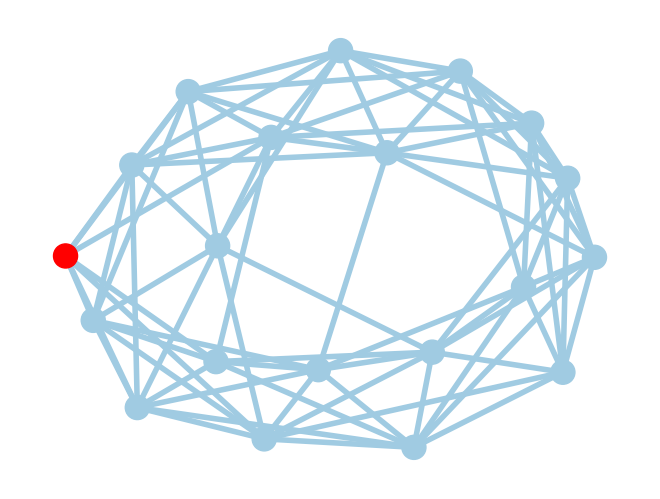

In [15]:
pos = nx.spring_layout(G, seed=63)  # Seed layout for reproducibility
color_nodes = ["#A0CBE2"]*N
color_nodes[nodes_p_dict['nodes_perturbed'][0]]='red'
color_edges = "#A0CBE2"
options = {
    "node_color": color_nodes,
    "edge_color": color_edges,
    "width": 4,
    "edge_cmap": plt.cm.Blues,
    "with_labels": False,
}
nx.draw(G, pos, **options)
plt.show()

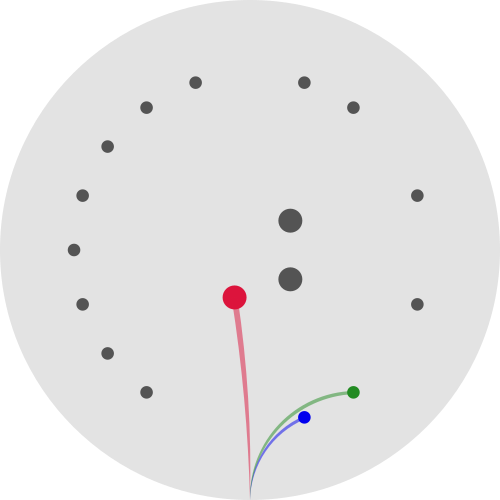

In [16]:
Pdisk_G

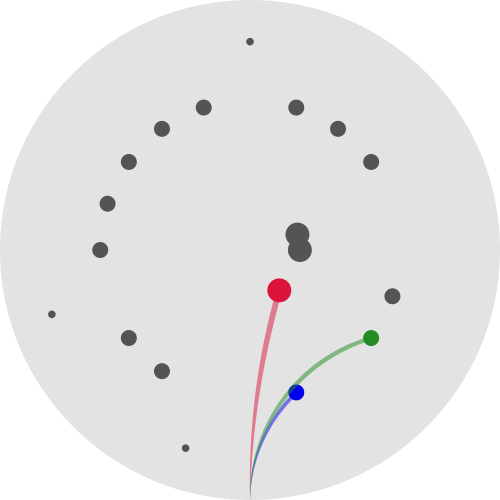

In [17]:
Pdisk_G_p